# Прогноз временного ряда многослойным персептроном (MLP): проверка применимости

**Проект:** taxi-demand-forecast (сквозной проект).
**Данные:** эталонная история симулятора M2: `make sim` (30 дней, seed 42), таблица `zone_metrics_5min` в `data/taxi.db`.
**Вопрос ноутбука:** *можно ли прогнозировать временные ряды этого города многослойным персептроном?*
Ноутбук не заменяет веху M3 (там multi-task LSTM). Это быстрый **proof-of-concept** перед ней:
он проверяет, что в данных есть извлекаемый сигнал и что даже простая полносвязная сеть
стабильно и с запасом обходит наивные прогнозы.

## Цели (выведены из плана `docs/plan-m3-ml.md`)

Продукт проекта — **предиктивная** ценовая политика: поднять тариф в зоне *до* того,
как там возникнет дефицит машин, а не после (реактивно). Для этого нужно за 15–30 минут знать
спрос, предложение и вероятность их столкновения. Отсюда цели и критерии успеха:

| # | Цель | Что предсказываем | Критерий «MLP работает» |
|---|------|-------------------|-------------------------|
| **Ц1** | Прогноз спроса | `requests` зоны в 5-минутке через **+15** и **+30** мин | MAE MLP ниже **лучшего** из наивных бейзлайнов на обоих горизонтах |
| **Ц2** | Прогноз предложения | `free_drivers` зоны через +15 / +30 мин | MAE MLP ниже лучшего бейзлайна на обоих горизонтах, выигрыш у «как сейчас» ≥ 10 % |
| **Ц3** | Раннее предупреждение о дефиците | метка дефицита по правилу контракта через +15 / +30 мин | F1 MLP выше, чем у «дефицит будет, если он есть сейчас», ROC-AUC ≥ 0.85 |
| **Ц4** | Надёжность вывода | — | результат устойчив к seed: разброс по 5 seed меньше выигрыша у бейзлайна |

Попутно ноутбук даёт эмпирические ответы на часть открытых вопросов §10 плана M3:
окно истории 3 / 6 / 12 ч (§10.5), точечный или накопленный таргет спроса (§10.6),
польза признака «возвращающиеся водители» (§4).

Правило дефицита по контракту (§3.8 плана M2): `free_drivers / max(requests, 1) < 0.5` **или** `unfulfilled > 0`.

## 1. Окружение и загрузка данных

Нужны `scikit-learn` и `matplotlib`; в `.venv` проекта их можно доставить командой
`.venv/bin/python -m pip install scikit-learn ipykernel`. MLP берём из `sklearn.neural_network`:
для proof-of-concept этого достаточно. Для сравнения с LSTM (§10) нужен ещё `torch`:
`.venv/bin/python -m pip install torch`.

In [1]:
import copy
import sqlite3
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    f1_score, log_loss, mean_absolute_error, mean_squared_error,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.precision", 3)
SEED = 42
np.random.seed(SEED)

# Палитра: факт — нейтральные чернила, MLP — синий, бейзлайны — фиксированные слоты.
C = {"fact": "#52514e", "mlp": "#2a78d6", "persist": "#eb6834", "seasonal": "#1baf7a",
     "profile": "#eda100", "ridge": "#6250d6", "lstm": "#d6336c", "grid": "#e4e3df"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b29", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "lines.linewidth": 1.6, "legend.frameon": False,
    "font.size": 9.5,
})

# Корень проекта — каталог с config.yaml (ноутбук может запускаться из notebooks/).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
DB = ROOT / "data" / "taxi.db"
assert DB.exists(), "Нет data/taxi.db — сгенерируйте историю: make sim"

con = sqlite3.connect(f"file:{DB}?mode=ro", uri=True)
metrics = pd.read_sql("SELECT * FROM zone_metrics_5min ORDER BY ts, zone_id", con, parse_dates=["ts"])
trips = pd.read_sql(
    "SELECT origin_zone, dest_zone, assigned_at, dropoff_at FROM trips WHERE status='completed'",
    con, parse_dates=["assigned_at", "dropoff_at"],
)
con.close()

ZONES = ["sleep-1", "sleep-2", "center", "office", "airport", "lounge"]
print(f"zone_metrics_5min: {len(metrics):,} строк, {metrics.ts.min()} … {metrics.ts.max()}")
print(f"trips (completed): {len(trips):,}")
metrics.head()

zone_metrics_5min: 51,840 строк, 2026-11-02 00:00:00 … 2026-12-01 23:55:00
trips (completed): 272,544


,ts,zone_id,requests,completed,unfulfilled,free_drivers,busy_drivers,avg_wait_min,supply_demand_ratio,is_rain,event,price_multiplier
0,2026-11-02,0,1,0,0,63,1,0.0,63.0,0,,1.0
1,2026-11-02,1,1,0,0,63,1,0.0,63.0,0,,1.0
2,2026-11-02,2,2,0,0,61,2,0.0,30.5,0,,1.0
3,2026-11-02,3,2,0,0,61,2,0.0,30.5,0,,1.0
4,2026-11-02,4,5,0,0,58,5,0.0,11.6,0,,1.0


Переводим длинную таблицу в матрицы `[время × зона]`: 8 640 пятиминуток × 6 зон.
Метка `ts` — начало 5-минутного окна, а снапшот парка снимается **на конце** окна.
Значит, строка `ts` становится известна в момент `ts + 5 мин`.

In [2]:
def wide(col):
    return metrics.pivot(index="ts", columns="zone_id", values=col).to_numpy(float)

TS = np.sort(metrics.ts.unique())
T, Z = len(TS), metrics.zone_id.nunique()
req, free, busy, unf = wide("requests"), wide("free_drivers"), wide("busy_drivers"), wide("unfulfilled")
rain = wide("is_rain")[:, 0]
event = (metrics.pivot(index="ts", columns="zone_id", values="event").fillna("") == "friday_evening").to_numpy(float)
deficit = ((free / np.maximum(req, 1) < 0.5) | (unf > 0)).astype(int)

step = np.arange(T)
slot = step % 288                     # номер 5-минутки в сутках
day = step // 288                     # номер дня (0 = пн 2026-11-02)
dow = day % 7                         # 0 = понедельник
weekend = (dow >= 5).astype(float)

summary = pd.DataFrame({
    "зона": ZONES,
    "спрос, заказов/5мин": req.mean(0),
    "своб. машин (ср.)": free.mean(0),
    "доля дефицита": deficit.mean(0),
}).set_index("зона")
print(f"T={T} шагов, Z={Z} зон; доля дефицитных 5-минуток по городу: {deficit.mean():.1%}")
summary

T=8640 шагов, Z=6 зон; доля дефицитных 5-минуток по городу: 18.8%


,"спрос, заказов/5мин",своб. машин (ср.),доля дефицита
зона,,,
sleep-1,2.596,13.922,0.238
sleep-2,2.598,67.481,0.051
center,8.139,130.067,0.044
office,7.462,44.627,0.179
airport,3.886,46.781,0.133
lounge,6.867,5.704,0.482


## 2. Разведочный анализ: есть ли что предсказывать?

MLP может научиться только тому, что в ряде действительно повторяется. Проверим три вещи:
суточную волну, автокорреляцию и то, насколько ряд зашумлён.

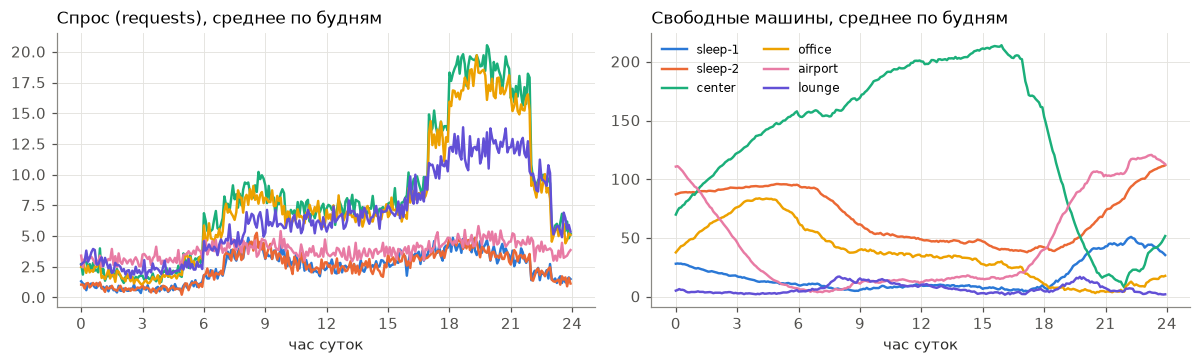

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
hours = np.arange(288) / 12
for ax, mat, title in [(axes[0], req, "Спрос (requests), среднее по будням"),
                       (axes[1], free, "Свободные машины, среднее по будням")]:
    wd = mat[weekend == 0].reshape(-1, 288, Z).mean(0)
    for z, color in zip(range(Z), ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]):
        ax.plot(hours, wd[:, z], color=color, label=ZONES[z])
    ax.set_title(title, loc="left"); ax.set_xlabel("час суток"); ax.set_xticks(range(0, 25, 3))
axes[1].legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

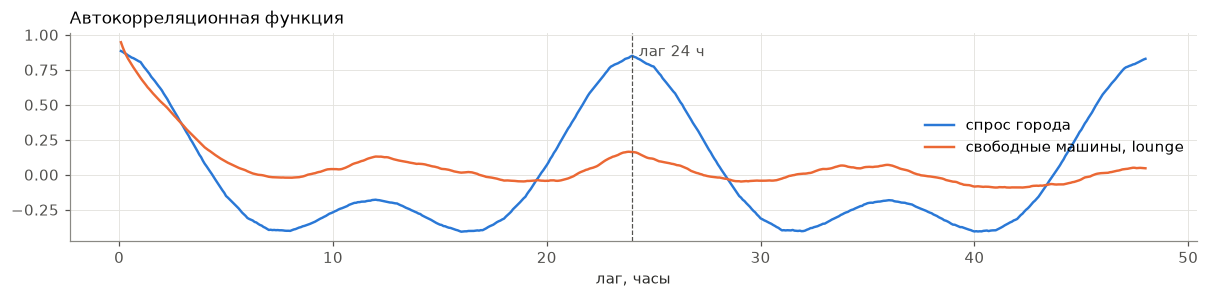

Спрос зоны в 5-минутке: среднее 5.26, дисперсия 21.67. У пуассоновского потока дисперсия ≈ среднему, поэтому даже идеальный прогноз будет ошибаться примерно на √λ ≈ 2.3 заказа.


In [4]:
def acf(x, lags):
    x = x - x.mean()
    return np.array([np.corrcoef(x[:-k], x[k:])[0, 1] for k in lags])

lags = np.arange(1, 2 * 288 + 1)
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.plot(lags / 12, acf(req.sum(1), lags), color=C["mlp"], label="спрос города")
ax.plot(lags / 12, acf(free[:, 5], lags), color=C["persist"], label="свободные машины, lounge")
ax.axvline(24, color=C["fact"], lw=0.8, ls="--"); ax.text(24.3, 0.85, "лаг 24 ч", color=C["fact"])
ax.set_xlabel("лаг, часы"); ax.set_title("Автокорреляционная функция", loc="left"); ax.legend()
plt.tight_layout(); plt.show()

r = req.ravel()
print(f"Спрос зоны в 5-минутке: среднее {r.mean():.2f}, дисперсия {r.var():.2f}. "
      f"У пуассоновского потока дисперсия ≈ среднему, поэтому даже идеальный прогноз будет ошибаться "
      f"примерно на √λ ≈ {np.sqrt(r.mean()):.1f} заказа.")

**Что видно:**

* Спрос имеет выраженную суточную волну с пиком около 18–20 ч в деловых зонах; ACF спроса города
  возвращается к высоким значениям на лаге 24 ч. Сезонная структура есть, её стоит подавать модели
  календарными признаками и значением «сутки назад».
* Свободные машины — ряд другой природы. Он почти не повторяется по суткам, ACF плавно спадает
  (это свойство случайного блуждания: парк дрейфует между зонами). Здесь важнее
  **текущее состояние и ближайшие высадки**, чем сезонность.
* Спрос в отдельной 5-минутке — это пуассоновский счётчик с маленьким λ ≈ 5. Значительная часть
  его вариации — неустранимый шум, поэтому R² будет скромным при любой модели. Сравнивать модели
  разумно с бейзлайнами и с «шумовым полом», а не с идеалом R² = 1.

## 3. Постановка задачи прогнозирования

**Одна модель на все зоны** (зона — one-hot признак), как предлагает план M3: данных на одну зону мало,
а закономерности у зон общие. Пример обучающей выборки — пара (зона *z*, момент *i*); прогноз строится
в момент, когда строка *i* закрыта (`ts_i + 5 мин`).

**Признаки** (всё строго из прошлого или заранее известно):

| Группа | Признаки |
|---|---|
| Спрос зоны | последние 12 пятиминуток (1 ч) поштучно + средние по получасам за окно *L* (дефолт 6 ч) |
| Свободные машины | последние 12 значений и получасовые средние **относительно текущего** уровня; сам текущий уровень |
| Занятые машины, спрос города | последние 12 пятиминуток |
| Календарь целевого момента | sin/cos времени суток, флаг выходного, флаг «пятничного вечера» (расписание события известно заранее) |
| Сезонный лаг | спрос зоны ровно сутки назад в целевом слоте |
| Среда | дождь сейчас, день недели (sin/cos) |
| **Возвращающиеся водители** | сколько уже назначенных поездок высадятся в зоне в ближайшие 15 / 30 мин. Время высадки фиксируется при назначении, поэтому это знание о прошлом, а не утечка |
| Зона | one-hot (6) |

**Таргеты (точечные, как в контракте `forecasts`):** `requests[i+3]`, `requests[i+6]` (+15 / +30 мин),
`free_drivers[i+3]`, `free_drivers[i+6]`. Для свободных машин сеть учится предсказывать **приращение**
относительно текущего уровня: так ряд со свойствами блуждания становится стационарным.

**Разбиение — целыми днями, в хронологическом порядке** (без перемешивания, иначе соседние
5-минутки утекут между выборками):

* день 0 — только история для лагов «сутки назад»;
* дни 1–21 — обучение; дни 22–23 — валидация (ранняя остановка, подбор гиперпараметров и порога);
* **дни 24–29 (6 суток, чт–вт) — тест**, в него входят и пятничный, и субботний вечер.

In [5]:
# Возвращающиеся водители: в момент K = ts_i + 5 мин считаем поездки, назначенные до K,
# с высадкой в зоне z в [K, K + H). Всё в минутах от начала симуляции.
t0 = pd.Timestamp(TS[0])
asg = ((trips.assigned_at - t0) / pd.Timedelta(minutes=1)).to_numpy()
drp = ((trips.dropoff_at - t0) / pd.Timedelta(minutes=1)).to_numpy()
dz = trips.dest_zone.to_numpy()

def returning(H):
    out = np.zeros((T, Z))
    K = 5 * step + 5
    for z in range(Z):
        a, d = asg[dz == z], drp[dz == z]
        o = np.argsort(d); a, d = a[o], d[o]
        lo, hi = np.searchsorted(d, K), np.searchsorted(d, K + H)
        out[:, z] = [(a[l:h] < k).sum() for l, h, k in zip(lo, hi, K)]
    return out

RET = {15: returning(15), 30: returning(30)}
print("Среднее число возвращающихся за 15 / 30 мин:", RET[15].mean().round(2), "/", RET[30].mean().round(2))

Среднее число возвращающихся за 15 / 30 мин: 10.95 / 11.88


In [6]:
START, HMAX = 288, 6              # первая точка с лагом «сутки назад»; макс. горизонт = 6 шагов
IDX = np.arange(START, T - HMAX)  # моменты прогноза i
HORIZONS = (3, 6)                 # +15 и +30 мин

def windows(x, L):
    # Окна x[i-L+1 .. i] для всех i из IDX: форма (len(IDX), L).
    return sliding_window_view(x, L)[IDX - L + 1]

def make_dataset(L=72, use_ret=True, target="point"):
    # Собрать X, Y (регрессия), Yc (метки дефицита) и meta = (i, z).
    assert L % 6 == 0 and L <= START
    city = req.sum(1) / Z
    Xs, Ys, Ycs, metas = [], [], [], []
    for z in range(Z):
        r, f = windows(req[:, z], L), windows(free[:, z], L)
        cur = f[:, -1:]
        parts = [
            r[:, -12:], r.reshape(len(IDX), -1, 6).mean(2),
            f[:, -12:] - cur, f.reshape(len(IDX), -1, 6).mean(2) - cur, cur,
            windows(busy[:, z], 12), windows(city, 12),
        ]
        for h in HORIZONS:
            j = IDX + h
            parts.append(np.c_[req[j - 288, z], np.sin(2 * np.pi * slot[j] / 288),
                               np.cos(2 * np.pi * slot[j] / 288), weekend[j], event[j, z]])
        parts.append(np.c_[rain[IDX], np.sin(2 * np.pi * dow[IDX] / 7), np.cos(2 * np.pi * dow[IDX] / 7)])
        if use_ret:
            parts.append(np.c_[RET[15][IDX, z], RET[30][IDX, z]])
        parts.append(np.tile(np.eye(Z)[z], (len(IDX), 1)))
        Xs.append(np.hstack(parts))
        if target == "point":
            yr = [req[IDX + h, z] for h in HORIZONS]
        else:  # накопленный спрос за (i, i+h]
            yr = [np.stack([req[IDX + k, z] for k in range(1, h + 1)]).sum(0) for h in HORIZONS]
        Ys.append(np.c_[(*yr, *[free[IDX + h, z] - free[IDX, z] for h in HORIZONS])])
        Ycs.append(np.c_[[deficit[IDX + h, z] for h in HORIZONS]].T)
        metas.append(np.c_[IDX, np.full(len(IDX), z)])
    return (np.vstack(Xs).astype(np.float32), np.vstack(Ys), np.vstack(Ycs), np.vstack(metas))

X, Y, Yc, META = make_dataset()
DAY = META[:, 0] // 288
TRN, VAL, TST = DAY <= 21, (DAY >= 22) & (DAY <= 23), DAY >= 24
I_T, Z_T = META[TST, 0], META[TST, 1]
TARGETS = ["спрос +15", "спрос +30", "своб. +15", "своб. +30"]
print(f"X: {X.shape}, признаков {X.shape[1]}; обучение {TRN.sum():,} / валидация {VAL.sum():,} / тест {TST.sum():,}")
print("Тестовые дни:", pd.to_datetime(TS[I_T]).normalize().unique().strftime("%a %d.%m").tolist())

X: (50076, 94), признаков 94; обучение 36,288 / валидация 3,456 / тест 10,332
Тестовые дни: ['Thu 26.11', 'Fri 27.11', 'Sat 28.11', 'Sun 29.11', 'Mon 30.11', 'Tue 01.12']


## 4. Бейзлайны

Нарочно простые модели, с которыми сравниваем сеть:

1. **«Как сейчас» (persistence)**: прогноз равен последнему наблюдению.
2. **Сезонный наив**: значение сутки назад в целевом слоте.
3. **Исторический профиль**: среднее по обучающим дням для той же зоны, слота и типа дня
   (будни / выходные). Это самый сильный наив для спроса, он почти совпадает с «истинной» λ
   спокойного дня.
4. **Ridge** — линейная регрессия на тех же признаках, что и MLP. Это не наив, а контроль:
   показывает, что даёт **нелинейность** персептрона сверх линейной модели.

In [7]:
def baseline_preds():
    # Прогнозы бейзлайнов на тесте в уровнях; колонки — как TARGETS.
    trn_mask = day <= 21
    prof = np.zeros((2, 288, 2, Z))  # [тип дня, слот, (req, free), зона]
    for wd in (0, 1):
        for s in range(288):
            m = trn_mask & (weekend == wd) & (slot == s)
            prof[wd, s, 0], prof[wd, s, 1] = req[m].mean(0), free[m].mean(0)
    out = {}
    out["как сейчас"] = np.c_[req[I_T, Z_T], req[I_T, Z_T], free[I_T, Z_T], free[I_T, Z_T]]
    out["сутки назад"] = np.c_[[(req if k < 2 else free)[I_T + h - 288, Z_T]
                                for k, h in enumerate((3, 6, 3, 6))]].T
    out["ист. профиль"] = np.c_[[prof[weekend[I_T + h].astype(int), slot[I_T + h], int(k >= 2), Z_T]
                                 for k, h in enumerate((3, 6, 3, 6))]].T
    return out

def to_levels(P):
    # Перевести прогноз (спрос, Δсвоб.) в уровни; отрицательные значения обрезаем.
    P = P.copy()
    P[:, 2:] += free[I_T, Z_T][:, None]
    return np.clip(P, 0, None)

Y_TEST = to_levels(Y[TST])          # факт в уровнях
BASE = baseline_preds()

## 5. Многослойный персептрон

Архитектура: вход (≈ 94 стандартизованных признака) → полносвязные скрытые слои с ReLU → 4 линейных
выхода (multi-output регрессия: спрос и Δсвоб. на двух горизонтах). Функция потерь — MSE
по стандартизованным таргетам, оптимизатор Adam, L2-регуляризация `alpha`.

Встроенный `early_stopping` в sklearn отрезает валидацию **случайной** долей строк, что для
временного ряда даёт утечку. Поэтому обучаем по эпохам через `partial_fit` и сами
останавливаемся по **валидационным дням** (patience = 10 эпох), сохраняя лучшие веса.
Скейлеры обучаются только на train.

In [8]:
def fit_mlp(X, Y, hidden=(128, 64), alpha=1e-2, seed=SEED, epochs=100, patience=10, classifier=False):
    # Обучение MLP с ранней остановкой по валидационным дням; возвращает (модель, скейлеры, история).
    sx = StandardScaler().fit(X[TRN])
    Xt, Xv = sx.transform(X[TRN]), sx.transform(X[VAL])
    if classifier:
        sy, Yt, Yv = None, Y[TRN], Y[VAL]
        model = MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, batch_size=256,
                              learning_rate_init=1e-3, random_state=seed)
        val_loss = lambda m: log_loss(Yv.ravel(), np.clip(m.predict_proba(Xv).ravel(), 1e-6, 1 - 1e-6))
    else:
        sy = StandardScaler().fit(Y[TRN])
        Yt, Yv = sy.transform(Y[TRN]), sy.transform(Y[VAL])
        model = MLPRegressor(hidden_layer_sizes=hidden, alpha=alpha, batch_size=256,
                             learning_rate_init=1e-3, random_state=seed)
        val_loss = lambda m: np.mean((m.predict(Xv) - Yv) ** 2)
    best, hist = (np.inf, None, -1), []
    for ep in range(epochs):
        if classifier and ep == 0:
            model.partial_fit(Xt, Yt, classes=[0, 1])
        else:
            model.partial_fit(Xt, Yt)
        vl = val_loss(model)
        hist.append((model.loss_, vl))
        if vl < best[0]:
            best = (vl, copy.deepcopy(model), ep)
        elif ep - best[2] >= patience:
            break
    return best[1], sx, sy, {"history": np.array(hist), "best_epoch": best[2], "val_loss": best[0]}

def predict_reg(model, sx, sy, X):
    return to_levels(sy.inverse_transform(model.predict(sx.transform(X[TST]))))

### 5.1. Подбор гиперпараметров (только по валидации)

Небольшая сетка: ширина/глубина и сила L2-регуляризации. Тест в выборе не участвует.

In [9]:
grid = [((64, 32), 1e-2), ((128, 64), 1e-2), ((128, 64), 1e-1), ((256, 128), 1e-1)]
rows, fits = [], {}
for hidden, alpha in grid:
    t = time.time()
    m, sx, sy, info = fit_mlp(X, Y, hidden, alpha)
    fits[(hidden, alpha)] = (m, sx, sy, info)
    rows.append({"скрытые слои": str(hidden), "alpha": alpha, "лучшая эпоха": info["best_epoch"],
                 "val MSE (станд.)": info["val_loss"], "время, с": time.time() - t})
grid_df = pd.DataFrame(rows).sort_values("val MSE (станд.)")
BEST = min(fits, key=lambda k: fits[k][3]["val_loss"])
print("Выбрано:", BEST)
grid_df

Выбрано: ((256, 128), 0.1)


,скрытые слои,alpha,лучшая эпоха,val MSE (станд.),"время, с"
3,"(256, 128)",0.10,6,0.436,4.569
0,"(64, 32)",0.01,13,0.442,2.129
1,"(128, 64)",0.01,5,0.448,2.305
2,"(128, 64)",0.10,6,0.450,2.501


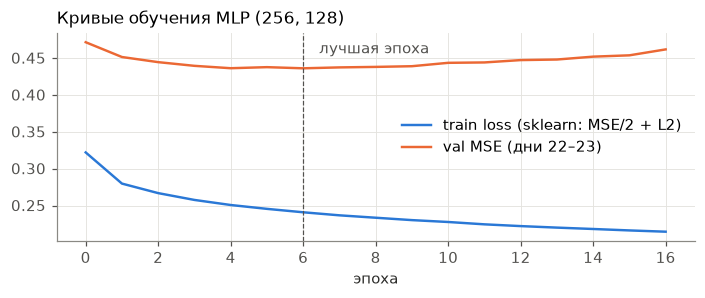

In [10]:
mlp, SX, SY, INFO = fits[BEST]
P_MLP = predict_reg(mlp, SX, SY, X)
ridge = Ridge(alpha=1.0).fit(SX.transform(X[TRN]), Y[TRN])
P_RIDGE = to_levels(ridge.predict(SX.transform(X[TST])))

h = INFO["history"]
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(h[:, 0], color=C["mlp"], label="train loss (sklearn: MSE/2 + L2)")
ax.plot(h[:, 1], color=C["persist"], label="val MSE (дни 22–23)")
ax.axvline(INFO["best_epoch"], color=C["fact"], ls="--", lw=0.8)
ax.text(INFO["best_epoch"] + 0.3, h[:, 1].max(), " лучшая эпоха", color=C["fact"], va="top")
ax.set_xlabel("эпоха"); ax.set_title(f"Кривые обучения MLP {BEST[0]}", loc="left"); ax.legend()
plt.tight_layout(); plt.show()

Валидационная ошибка выходит на плато за несколько эпох, дальше сеть начинает подгонять шум
обучающих дней. Ранняя остановка по дням это отсекает.

## 6. Результаты прогноза на тесте (дни 24–29)

Ниже MAE и RMSE в натуральных единицах (заказов или машин на зону в 5-минутке). Строка
«шумовой пол» — оценка ошибки, которую дал бы *идеальный* прогноз пуассоновского спроса
(λ берётся из прогноза MLP): ниже неё по спросу не опустится ни одна модель.

In [11]:
def score_table(preds, y=Y_TEST):
    rows = {}
    for name, P in preds.items():
        rows[name] = {**{(t, "MAE"): mean_absolute_error(y[:, k], P[:, k]) for k, t in enumerate(TARGETS)},
                      **{(t, "RMSE"): np.sqrt(mean_squared_error(y[:, k], P[:, k])) for k, t in enumerate(TARGETS)}}
    df = pd.DataFrame(rows).T
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    return df[[(t, m) for t in TARGETS for m in ("MAE", "RMSE")]]

ALL = {**BASE, "Ridge (линейная)": P_RIDGE, "MLP": P_MLP}
res = score_table(ALL)

# Шумовой пол спроса: E|Pois(λ) − λ| и √λ при λ = прогноз MLP.
rng = np.random.default_rng(SEED)
floor = {}
for k in (0, 1):
    lam = np.maximum(P_MLP[:, k], 1e-3)
    draws = rng.poisson(lam[None, :], size=(200, len(lam)))
    floor[(TARGETS[k], "MAE")] = np.abs(draws - lam).mean()
    floor[(TARGETS[k], "RMSE")] = np.sqrt(lam.mean())
res.loc["шумовой пол (Пуассон)"] = pd.Series(floor)

naive = ["как сейчас", "сутки назад", "ист. профиль"]
gain = pd.DataFrame({t: [1 - res.loc["MLP", (t, "MAE")] / res.loc[naive, (t, "MAE")].min(),
                         1 - res.loc["MLP", (t, "MAE")] / res.loc["как сейчас", (t, "MAE")],
                         1 - res.loc["MLP", (t, "MAE")] / res.loc["Ridge (линейная)", (t, "MAE")]]
                     for t in TARGETS},
                    index=["выигрыш MAE у лучшего наива", "… у «как сейчас»", "… у Ridge"])
display(res.style.format("{:.3f}", na_rep="—").highlight_min(axis=0, subset=pd.IndexSlice[res.index[:-1], :],
                                                             props="font-weight:bold; color:#2a78d6"))
display(gain.style.format("{:+.1%}"))

,спрос +15,спрос +30,своб. +15,своб. +30
выигрыш MAE у лучшего наива,+4.0%,+2.7%,+19.3%,+18.3%
… у «как сейчас»,+25.9%,+26.4%,+19.3%,+18.3%
… у Ridge,+2.1%,+2.2%,+2.3%,+3.3%


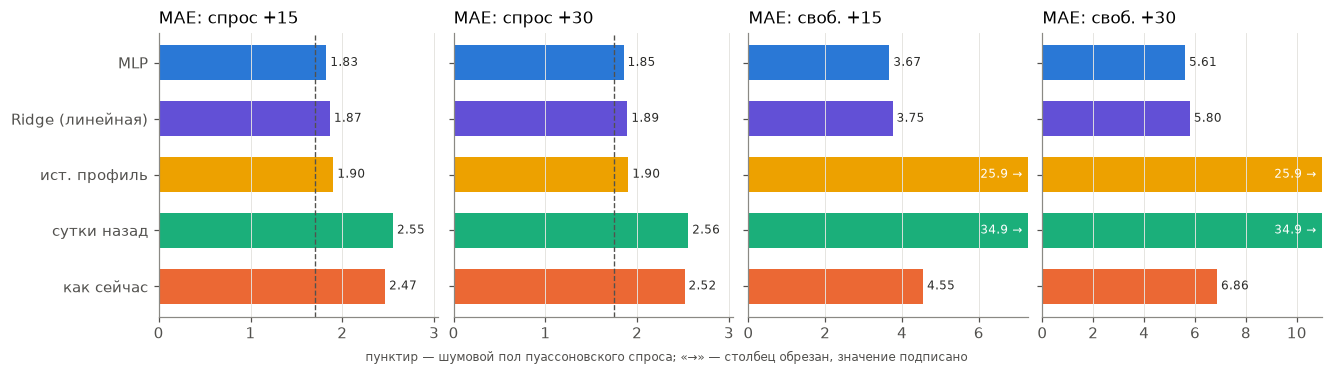

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), layout="constrained")
order = ["как сейчас", "сутки назад", "ист. профиль", "Ridge (линейная)", "MLP"]
colors = [C["persist"], C["seasonal"], C["profile"], C["ridge"], C["mlp"]]
for k, (ax, t) in enumerate(zip(axes, TARGETS)):
    vals = [res.loc[n, (t, "MAE")] for n in order]
    xmax = min(max(vals) * 1.25, sorted(vals)[2] * 1.6)   # обрезаем ось, если наив «улетает»
    ax.barh(range(len(order)), np.minimum(vals, xmax), color=colors, height=0.62)
    for y_, v in enumerate(vals):
        if v > xmax:   # столбец обрезан — подпись внутри, со стрелкой
            ax.text(xmax * 0.98, y_, f"{v:.1f} →", va="center", ha="right", fontsize=8, color="white")
        else:
            ax.text(v, y_, f" {v:.2f}", va="center", fontsize=8, color="#2b2b29")
    if k < 2:
        ax.axvline(res.loc["шумовой пол (Пуассон)", (t, "MAE")], color=C["fact"], ls="--", lw=0.9)
    ax.set_xlim(0, xmax)
    ax.set_yticks(range(len(order)), order if k == 0 else [""] * len(order))
    ax.set_title(f"MAE: {t}", loc="left"); ax.grid(axis="y", visible=False)
fig.supxlabel("пунктир — шумовой пол пуассоновского спроса; «→» — столбец обрезан, значение подписано",
              fontsize=8, color=C["fact"])
plt.show()

### 6.1. Факт и прогноз на тестовых днях

Две характерные зоны: **center** (большой спрос, машин в избытке) и **lounge** (хронический
дефицит машин). Прогноз на +30 мин сопоставлен с фактом **в целевой момент**.

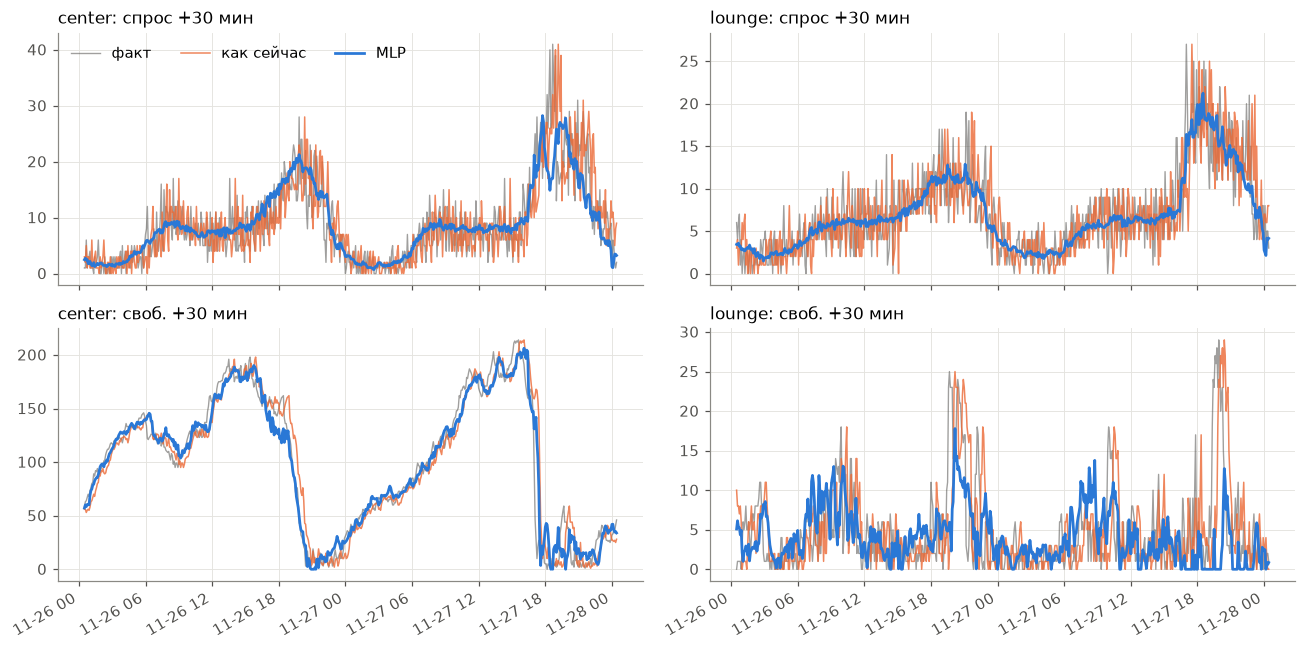

In [13]:
def series_for(zone, k, P, d0=24, d1=26):
    m = (Z_T == zone) & (I_T // 288 >= d0) & (I_T // 288 < d1)
    tgt_ts = pd.to_datetime(TS[I_T[m] + HORIZONS[k % 2]])
    return tgt_ts, Y_TEST[m, k], P[m, k], BASE["как сейчас"][m, k]

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for col, zone in enumerate((2, 5)):
    for row, k in enumerate((1, 3)):
        ax = axes[row, col]
        tt, y, p, pers = series_for(zone, k, P_MLP)
        ax.plot(tt, y, color=C["fact"], lw=0.9, alpha=0.55, label="факт")
        ax.plot(tt, pers, color=C["persist"], lw=1.0, alpha=0.8, label="как сейчас")
        ax.plot(tt, p, color=C["mlp"], lw=1.8, label="MLP")
        ax.set_title(f"{ZONES[zone]}: {TARGETS[k]} мин", loc="left")
axes[0, 0].legend(ncol=3)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

Прогноз спроса у MLP — гладкая кривая, которая повторяет суточную волну и её всплески, а не
дёргается вслед за пуассоновским шумом, как «как сейчас». По свободным машинам «как сейчас»
сдвинут вправо на горизонт (запаздывание реактивной политики из §11 плана M3 видно наглядно),
а MLP заранее учитывает возвращающиеся машины и уход машин на заказы.

,MAE спрос+30 MLP,MAE спрос+30 наив*,MAE своб.+30 MLP,MAE своб.+30 как сейчас,выигрыш спрос,выигрыш своб.
sleep-1,1.33,1.33,4.07,4.39,+0%,+7%
sleep-2,1.31,1.34,4.06,5.17,+2%,+21%
center,2.50,2.52,9.75,11.93,+0%,+18%
office,2.34,2.40,6.38,7.74,+2%,+18%
airport,1.56,1.62,5.83,8.26,+4%,+29%
lounge,2.07,2.22,3.54,3.70,+7%,+4%


* наив — лучший из трёх наивов для каждой зоны отдельно


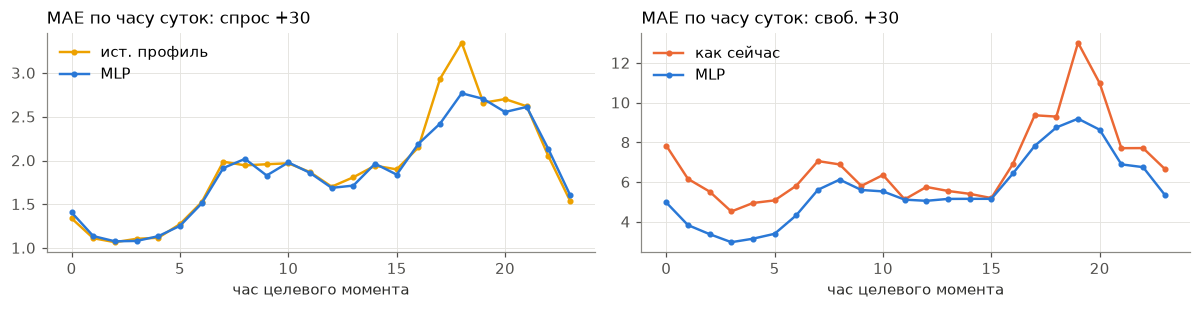

In [14]:
# Ошибка по зонам и по часу суток (горизонт +30).
by_zone = pd.DataFrame({
    "MAE спрос+30 MLP": [mean_absolute_error(Y_TEST[Z_T == z, 1], P_MLP[Z_T == z, 1]) for z in range(Z)],
    "MAE спрос+30 наив*": [min(mean_absolute_error(Y_TEST[Z_T == z, 1], BASE[n][Z_T == z, 1]) for n in naive) for z in range(Z)],
    "MAE своб.+30 MLP": [mean_absolute_error(Y_TEST[Z_T == z, 3], P_MLP[Z_T == z, 3]) for z in range(Z)],
    "MAE своб.+30 как сейчас": [mean_absolute_error(Y_TEST[Z_T == z, 3], BASE["как сейчас"][Z_T == z, 3]) for z in range(Z)],
}, index=ZONES)
by_zone["выигрыш спрос"] = 1 - by_zone.iloc[:, 0] / by_zone.iloc[:, 1]
by_zone["выигрыш своб."] = 1 - by_zone.iloc[:, 2] / by_zone.iloc[:, 3]
display(by_zone.style.format("{:.2f}").format("{:+.0%}", subset=["выигрыш спрос", "выигрыш своб."]))
print("* наив — лучший из трёх наивов для каждой зоны отдельно")

hour = slot[I_T + 6] // 12
fig, axes = plt.subplots(1, 2, figsize=(11, 2.9), sharex=True)
for ax, k, base_name in [(axes[0], 1, "ист. профиль"), (axes[1], 3, "как сейчас")]:
    for name, P, c in [(base_name, BASE[base_name], C["profile"] if k == 1 else C["persist"]), ("MLP", P_MLP, C["mlp"])]:
        e = pd.Series(np.abs(Y_TEST[:, k] - P[:, k])).groupby(hour).mean()
        ax.plot(e.index, e.values, marker="o", ms=3, color=c, label=name)
    ax.set_title(f"MAE по часу суток: {TARGETS[k]}", loc="left"); ax.set_xlabel("час целевого момента")
    ax.legend()
plt.tight_layout(); plt.show()

По **свободным машинам** выигрыш есть во всех зонах. По **спросу** он мал (0–7 %): лучший наив
здесь — исторический профиль, а в спокойных зонах (sleep-1, center) он уже почти совпадает
с истинной λ, и выигрывать MLP может только на отклонениях от профиля (дождь, события). Абсолютная ошибка растёт в вечерний пик: там больше λ, а значит,
и пуассоновский шум (√λ). Для свободных машин MLP особенно выигрывает в часы перестройки
парка, когда текущее состояние быстрее всего устаревает.

### 6.2. Дождь: реагирует ли модель на внешний шок?

Дождь умножает спрос на 1.4 (и время в пути — тоже). В тестовые дни дождевые эпизоды есть (27.11 и 30.11),
поэтому сравним ошибку отдельно на окнах, где в целевой момент идёт дождь. Таких окон немного, оценка грубая.

In [15]:
rain_t = rain[I_T + 6] == 1
rows = {}
for name, P in [("ист. профиль", BASE["ист. профиль"]), ("как сейчас", BASE["как сейчас"]), ("MLP", P_MLP)]:
    rows[name] = {("спрос +30", "дождь"): mean_absolute_error(Y_TEST[rain_t, 1], P[rain_t, 1]),
                  ("спрос +30", "без дождя"): mean_absolute_error(Y_TEST[~rain_t, 1], P[~rain_t, 1]),
                  ("своб. +30", "дождь"): mean_absolute_error(Y_TEST[rain_t, 3], P[rain_t, 3]),
                  ("своб. +30", "без дождя"): mean_absolute_error(Y_TEST[~rain_t, 3], P[~rain_t, 3])}
print(f"Окон (зона × 5 мин) с дождём в целевой момент: {rain_t.sum()} из {len(rain_t)}")
pd.DataFrame(rows).T.style.format("{:.2f}")

Окон (зона × 5 мин) с дождём в целевой момент: 288 из 10332


Именно в дождь, когда спрос отрывается от привычного профиля, разница между подходами видна сильнее
всего. Исторический профиль ничего не знает о дожде, «как сейчас» реагирует с запозданием, а MLP получает
флаг дождя и свежие лаги и ошибается заметно меньше обоих (по спросу примерно на треть меньше профиля).
На обычных окнах MLP и профиль идут почти вровень. Получается, что выигрыш персептрона сосредоточен
в нештатных ситуациях, а для ценовой политики важны именно они.

## 7. Раннее предупреждение о дефиците (Ц3)

Ту же архитектуру переводим в бинарный классификатор (`MLPClassifier`, 2 сигмоидных выхода:
дефицит через +15 и +30 мин). Порог решения подбирается по F1 **на валидации** и затем
переносится на тест. Сравниваем с тремя вариантами:

* **«дефицит сейчас»** — persistence метки;
* **правило по регрессионному прогнозу MLP** — к прогнозам спроса и свободных машин применяем правило
  контракта (без `unfulfilled`);
* всегда «нет дефицита» даёт F1 = 0, accuracy ≈ 82 %. Поэтому accuracy здесь неинформативна.

In [16]:
clf, SXc, _, INFOc = fit_mlp(X, Yc, BEST[0], BEST[1], classifier=True)
pv = clf.predict_proba(SXc.transform(X[VAL]))
ps = clf.predict_proba(SXc.transform(X[TST]))
YC_T = Yc[TST]
ths = np.linspace(0.1, 0.9, 81)
rows = []
for k, hz in enumerate(("+15", "+30")):
    th = ths[np.argmax([f1_score(Yc[VAL][:, k], pv[:, k] >= t) for t in ths])]
    cand = {
        "дефицит сейчас": (deficit[I_T, Z_T], deficit[I_T, Z_T]),
        "правило по прогнозу MLP": ((P_MLP[:, 2 + k] / np.maximum(P_MLP[:, k], 1) < 0.5).astype(int),
                                    -P_MLP[:, 2 + k] / np.maximum(P_MLP[:, k], 1)),
        f"MLP-классификатор (порог {th:.2f})": ((ps[:, k] >= th).astype(int), ps[:, k]),
    }
    for name, (yhat, score) in cand.items():
        rows.append({"горизонт": hz, "метод": name,
                     "precision": precision_score(YC_T[:, k], yhat), "recall": recall_score(YC_T[:, k], yhat),
                     "F1": f1_score(YC_T[:, k], yhat), "ROC-AUC": roc_auc_score(YC_T[:, k], score)})
clf_res = pd.DataFrame(rows).set_index(["горизонт", "метод"])
print(f"Доля дефицита на тесте: {YC_T.mean():.1%}")
clf_res

Доля дефицита на тесте: 18.4%


precision  recall     F1  ROC-AUC
горизонт метод                                                            
+15      дефицит сейчас                      0.553   0.553  0.553    0.726
         правило по прогнозу MLP             0.647   0.582  0.613    0.923
         MLP-классификатор (порог 0.33)      0.569   0.782  0.659    0.918
+30      дефицит сейчас                      0.518   0.518  0.518    0.705
         правило по прогнозу MLP             0.562   0.480  0.518    0.894
         MLP-классификатор (порог 0.23)      0.493   0.819  0.616    0.897

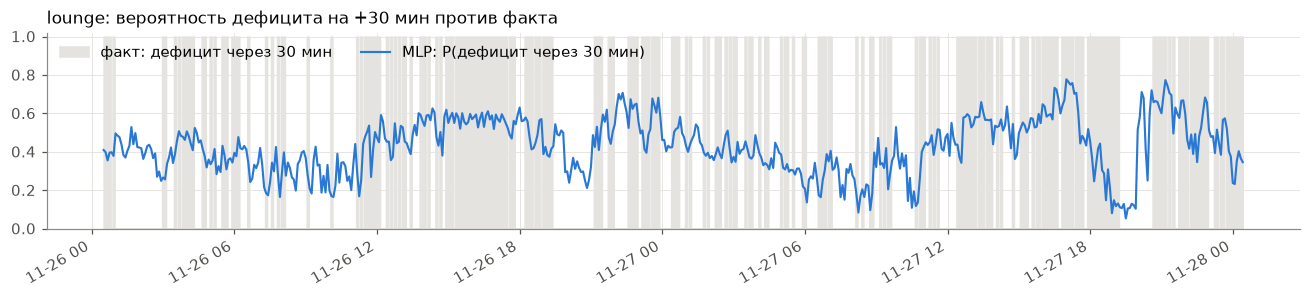

In [17]:
m = (Z_T == 5) & (I_T // 288 >= 24) & (I_T // 288 < 26)
tt = pd.to_datetime(TS[I_T[m] + 6])
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.fill_between(tt, 0, YC_T[m, 1], step="mid", color=C["grid"], label="факт: дефицит через 30 мин")
ax.plot(tt, ps[m, 1], color=C["mlp"], lw=1.4, label="MLP: P(дефицит через 30 мин)")
ax.set_ylim(0, 1.02); ax.set_title("lounge: вероятность дефицита на +30 мин против факта", loc="left")
ax.legend(loc="upper left", ncol=2); fig.autofmt_xdate(); plt.tight_layout(); plt.show()

MLP-классификатор отделяет дефицитные окна от нормальных заметно лучше, чем persistence:
ROC-AUC около 0.9, а F1 выше на обоих горизонтах. Для политики M6 важно, что выдаётся
**вероятность**: порог/шаг/потолок тарифа можно настраивать поверх неё, не переобучая модель.

## 8. Эксперименты к открытым вопросам M3

### 8.1. Окно истории: 3 / 6 / 12 ч (§10.5)

Выбираем по валидационной ошибке; тестовые значения приведены для справки.

In [18]:
def eval_variant(**kw):
    Xv_, Yv_, _, _ = make_dataset(**kw)
    m, sx, sy, info = fit_mlp(Xv_, Yv_, *BEST)
    P = predict_reg(m, sx, sy, Xv_)
    return info["val_loss"], [mean_absolute_error(Y_TEST[:, k], P[:, k]) for k in range(4)], Xv_.shape[1]

rows = []
for L in (36, 72, 144):
    vl, maes, nf = eval_variant(L=L)
    rows.append({"окно": f"{L // 12} ч", "признаков": nf, "val MSE": vl, **dict(zip([f"тест MAE {t}" for t in TARGETS], maes))})
win_df = pd.DataFrame(rows).set_index("окно")
win_df

,признаков,val MSE,тест MAE спрос +15,тест MAE спрос +30,тест MAE своб. +15,тест MAE своб. +30
окно,,,,,,
3 ч,82,0.454,1.827,1.858,3.707,5.645
6 ч,94,0.436,1.826,1.852,3.669,5.606
12 ч,118,0.442,1.841,1.859,3.703,5.662


### 8.2. Признак «возвращающиеся водители» (§4)

In [19]:
vl, maes, _ = eval_variant(use_ret=False)
abl = pd.DataFrame({"с признаком": [res.loc["MLP", (t, "MAE")] for t in TARGETS], "без признака": maes}, index=TARGETS)
abl["эффект"] = abl["без признака"] / abl["с признаком"] - 1
abl.style.format("{:.3f}").format("{:+.1%}", subset=["эффект"])

,с признаком,без признака,эффект
спрос +15,1.826,1.826,-0.0%
спрос +30,1.852,1.849,-0.1%
своб. +15,3.669,4.140,+12.8%
своб. +30,5.606,5.839,+4.2%


### 8.3. Точечный или накопленный таргет спроса (§10.6)

Абсолютные MAE несравнимы (накопленный спрос за 30 мин в шесть раз больше точечного),
поэтому сравниваем **WAPE** = Σ|ошибка| / Σ факт: какую долю объёма модель ошибается.

In [20]:
Xc_, Ycum, _, _ = make_dataset(target="cum")
m_c, sx_c, sy_c, _ = fit_mlp(Xc_, Ycum, *BEST)
Pc = sy_c.inverse_transform(m_c.predict(sx_c.transform(Xc_[TST])))
wape = lambda y, p: np.abs(y - p).sum() / y.sum()
cum_df = pd.DataFrame({
    "точечный бакет": [wape(Y_TEST[:, k], P_MLP[:, k]) for k in (0, 1)],
    "накопленный (i, i+h]": [wape(Ycum[TST][:, k], np.clip(Pc[:, k], 0, None)) for k in (0, 1)],
}, index=["+15 мин", "+30 мин"])
cum_df.style.format("{:.1%}")

,точечный бакет,"накопленный (i, i+h]"
+15 мин,34.0%,20.8%
+30 мин,34.5%,15.9%


Накопленный таргет предсказывается с относительной ошибкой в 1.6–2.2 раза меньше (чем длиннее горизонт, тем сильнее эффект): при сложении
нескольких 5-минуток пуассоновский шум частично гасится. Для ценовой политики (сколько заказов
придёт за горизонт) это аргумент за накопленный таргет или за то, чтобы хранить оба.

## 9. Устойчивость к seed (Ц4)

Переобучаем выбранную архитектуру с пятью разными seed (инициализация весов и порядок
мини-батчей). Если разброс меньше выигрыша у бейзлайна, вывод не случайность одного запуска.

In [21]:
seed_maes = []
for s in range(5):
    m, sx, sy, _ = fit_mlp(X, Y, *BEST, seed=s)
    P = predict_reg(m, sx, sy, X)
    seed_maes.append([mean_absolute_error(Y_TEST[:, k], P[:, k]) for k in range(4)])
seed_maes = np.array(seed_maes)
best_naive = np.array([res.loc[naive, (t, "MAE")].min() for t in TARGETS])
seed_df = pd.DataFrame({"MLP MAE, среднее": seed_maes.mean(0), "± std": seed_maes.std(0),
                        "худший seed": seed_maes.max(0), "лучший наив": best_naive}, index=TARGETS)
seed_df["запас (наив − среднее) / std"] = (best_naive - seed_maes.mean(0)) / seed_maes.std(0)
seed_df

,"MLP MAE, среднее",± std,худший seed,лучший наив,запас (наив − среднее) / std
спрос +15,1.837,0.022,1.880,1.902,2.909
спрос +30,1.851,0.015,1.865,1.904,3.588
своб. +15,3.727,0.044,3.795,4.549,18.643
своб. +30,5.651,0.115,5.859,6.864,10.548


## 10. LSTM: окупается ли рекуррентность?

План M3 делает ставку на LSTM. Проверим на тех же данных, тех же таргетах, том же разбиении днями
и той же ранней остановке по валидационным дням, что она даёт **сверх MLP**.

**Честное сравнение по информации.** LSTM получает ту же информацию, что и MLP, но в другой форме:

* **последовательность** 72 шага × 11 каналов (окно 6 ч, как дефолт MLP): спрос зоны, свободные машины
  относительно текущего уровня, занятые, спрос города, дождь, sin/cos слота, выходной, событие,
  возвращающиеся водители на 15 / 30 мин. MLP видит то же окно, но сжатым в 12 последних значений и
  получасовые средние; LSTM — каждую пятиминутку;
* **статические признаки** (22): текущий уровень свободных машин, календарь целевого момента и сезонный
  лаг на обоих горизонтах, день недели, возвращающиеся водители, one-hot зоны.

Архитектура: `LSTM(11 → hidden)`, последнее скрытое состояние склеивается со статикой и идёт в голову
`Linear → ReLU → Dropout(0.1) → Linear(4)`. Потери — MSE по стандартизованным таргетам (как у MLP),
оптимизатор AdamW, обрезка градиента 1.0, patience 8 эпох. Обучение на GPU Apple (MPS), если он есть:
на CPU эпоха идёт ≈ 15–20 с, на MPS ≈ 2 с. На MPS обучение не бит-в-бит детерминировано,
поэтому устойчивость, как и для MLP, проверяем пятью seed (§10.4).

In [22]:
import torch
import torch.nn as nn

DEV = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("torch", torch.__version__, "| устройство:", DEV)


def make_seq_dataset(L=72):
    # Последовательности [N, L, 11] и статические признаки [N, 22]; порядок строк как в make_dataset.
    city = req.sum(1) / Z
    sin_s, cos_s = np.sin(2 * np.pi * slot / 288), np.cos(2 * np.pi * slot / 288)
    Xs, Ss = [], []
    for z in range(Z):
        cur = free[IDX, z][:, None]
        chans = [windows(req[:, z], L), windows(free[:, z], L) - cur, windows(busy[:, z], L),
                 windows(city, L), windows(rain, L), windows(sin_s, L), windows(cos_s, L),
                 windows(weekend, L), windows(event[:, z], L),
                 windows(RET[15][:, z], L), windows(RET[30][:, z], L)]
        Xs.append(np.stack(chans, axis=-1))
        stat = [cur]
        for h in HORIZONS:
            j = IDX + h
            stat.append(np.c_[req[j - 288, z], np.sin(2 * np.pi * slot[j] / 288),
                              np.cos(2 * np.pi * slot[j] / 288), weekend[j], event[j, z]])
        stat.append(np.c_[rain[IDX], np.sin(2 * np.pi * dow[IDX] / 7), np.cos(2 * np.pi * dow[IDX] / 7)])
        stat.append(np.c_[RET[15][IDX, z], RET[30][IDX, z]])
        stat.append(np.tile(np.eye(Z)[z], (len(IDX), 1)))
        Ss.append(np.hstack(stat))
    return np.vstack(Xs).astype(np.float32), np.vstack(Ss).astype(np.float32)


class LSTMNet(nn.Module):
    def __init__(self, f_seq, f_stat, n_out, hidden=64, layers=1, head=64, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(f_seq, hidden, num_layers=layers, batch_first=True,
                            dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Linear(hidden + f_stat, head), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(head, n_out))

    def forward(self, xs, xc):
        _, (h, _) = self.lstm(xs)
        return self.head(torch.cat([h[-1], xc], dim=1))


def fit_lstm(XS, XC, Y, hidden=64, layers=1, lr=2e-3, wd=1e-4, seed=SEED, epochs=60, patience=8,
             classifier=False, batch=256):
    # Обучение LSTM с ранней остановкой по валидационным дням; возвращает (predict(mask), info).
    torch.manual_seed(seed); np.random.seed(seed)
    flat = XS[TRN].reshape(-1, XS.shape[2])
    ms, ss = flat.mean(0), flat.std(0) + 1e-6          # нормировка каналов — только по train
    sc = StandardScaler().fit(XC[TRN])
    prep = lambda m: (torch.tensor((XS[m] - ms) / ss, device=DEV),
                      torch.tensor(sc.transform(XC[m]), dtype=torch.float32, device=DEV))
    sy = None
    if classifier:
        Yt, Yv = Y[TRN].astype(np.float32), Y[VAL].astype(np.float32)
        loss_fn = nn.BCEWithLogitsLoss()
    else:
        sy = StandardScaler().fit(Y[TRN])
        Yt, Yv = sy.transform(Y[TRN]).astype(np.float32), sy.transform(Y[VAL]).astype(np.float32)
        loss_fn = nn.MSELoss()
    (xs_t, xc_t), (xs_v, xc_v) = prep(TRN), prep(VAL)
    yt, yv = torch.tensor(Yt, device=DEV), torch.tensor(Yv, device=DEV)
    net = LSTMNet(XS.shape[2], XC.shape[1], Y.shape[1], hidden, layers).to(DEV)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
    g = torch.Generator().manual_seed(seed)
    best, hist = (np.inf, None, -1), []
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(yt), generator=g).to(DEV); tl = 0.0
        for b in range(0, len(perm), batch):
            ix = perm[b:b + batch]
            opt.zero_grad()
            loss = loss_fn(net(xs_t[ix], xc_t[ix]), yt[ix])
            loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
            tl += loss.item() * len(ix)
        net.eval()
        with torch.no_grad():
            vl = loss_fn(net(xs_v, xc_v), yv).item()
        hist.append((tl / len(yt), vl))
        if vl < best[0]:
            best = (vl, copy.deepcopy(net.state_dict()), ep)
        elif ep - best[2] >= patience:
            break
    net.load_state_dict(best[1]); net.eval()

    def predict(mask):
        xs, xc = prep(mask)
        with torch.no_grad():
            out = torch.cat([net(xs[b:b + 4096], xc[b:b + 4096]) for b in range(0, len(xs), 4096)]).cpu().numpy()
        return 1 / (1 + np.exp(-out)) if classifier else sy.inverse_transform(out)

    n_par = sum(p.numel() for p in net.parameters())
    return predict, {"history": np.array(hist), "best_epoch": best[2], "val_loss": best[0], "params": n_par}


XS, XC = make_seq_dataset()
print(f"последовательности: {XS.shape}, статика: {XC.shape}")

torch 2.15.0 | устройство: mps


последовательности: (50076, 72, 11), статика: (50076, 22)


### 10.1. Подбор гиперпараметров LSTM (только по валидации)

Ширина скрытого состояния и число рекуррентных слоёв. Выбор, как и для MLP, по val MSE.

In [23]:
lstm_grid = [(64, 1, 2e-3), (128, 1, 1e-3), (64, 2, 2e-3), (128, 2, 1e-3)]
rows, lstm_fits = [], {}
for hidden, layers, lr in lstm_grid:
    t = time.time()
    pr, info = fit_lstm(XS, XC, Y, hidden, layers, lr)
    info["time"] = time.time() - t
    lstm_fits[(hidden, layers, lr)] = (pr, info)
    rows.append({"hidden": hidden, "слоёв LSTM": layers, "lr": lr, "параметров": info["params"],
                 "лучшая эпоха": info["best_epoch"], "val MSE (станд.)": info["val_loss"], "время, с": info["time"]})
lstm_grid_df = pd.DataFrame(rows).sort_values("val MSE (станд.)")
BEST_LSTM = min(lstm_fits, key=lambda k: lstm_fits[k][1]["val_loss"])
lstm_pred, LINFO = lstm_fits[BEST_LSTM]
P_LSTM = to_levels(lstm_pred(TST))
mlp_params = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
print(f"Выбрано: hidden={BEST_LSTM[0]}, слоёв={BEST_LSTM[1]}, lr={BEST_LSTM[2]}  "
      f"(val MSE {LINFO['val_loss']:.3f} против {INFO['val_loss']:.3f} у MLP)")
print(f"Параметров: LSTM {LINFO['params']:,} · MLP {mlp_params:,}")
lstm_grid_df

Выбрано: hidden=64, слоёв=1, lr=0.002  (val MSE 0.421 против 0.436 у MLP)
Параметров: LSTM 25,540 · MLP 57,732


,hidden,слоёв LSTM,lr,параметров,лучшая эпоха,val MSE (станд.),"время, с"
0,64,1,0.002,25540,4,0.421,36.468
3,128,2,0.001,214212,11,0.422,350.510
2,64,2,0.002,58820,8,0.428,94.982
1,128,1,0.001,82116,6,0.428,101.000


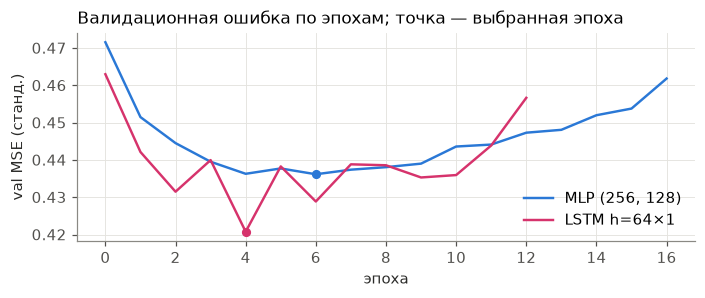

In [24]:
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(INFO["history"][:, 1], color=C["mlp"], label=f"MLP {BEST[0]}")
ax.plot(LINFO["history"][:, 1], color=C["lstm"], label=f"LSTM h={BEST_LSTM[0]}×{BEST_LSTM[1]}")
for inf, c in ((INFO, C["mlp"]), (LINFO, C["lstm"])):
    ax.plot(inf["best_epoch"], inf["val_loss"], "o", color=c, ms=5)
ax.set_xlabel("эпоха"); ax.set_ylabel("val MSE (станд.)")
ax.set_title("Валидационная ошибка по эпохам; точка — выбранная эпоха", loc="left"); ax.legend()
plt.tight_layout(); plt.show()

### 10.2. MLP против LSTM на тесте (дни 24–29)

Те же метрики, что в §6. «Δ» — насколько LSTM лучше MLP (положительное значение = LSTM ошибается меньше).

In [25]:
res2 = score_table({**ALL, "LSTM": P_LSTM})
res2.loc["шумовой пол (Пуассон)"] = res.loc["шумовой пол (Пуассон)"]
display(res2.style.format("{:.3f}", na_rep="—").highlight_min(axis=0, subset=pd.IndexSlice[res2.index[:-1], :],
                                                               props="font-weight:bold; color:#2a78d6"))

best_naive_mae = np.array([res.loc[naive, (t, "MAE")].min() for t in TARGETS])
cmp_df = pd.DataFrame({
    "MAE MLP": [res2.loc["MLP", (t, "MAE")] for t in TARGETS],
    "MAE LSTM": [res2.loc["LSTM", (t, "MAE")] for t in TARGETS],
    "RMSE MLP": [res2.loc["MLP", (t, "RMSE")] for t in TARGETS],
    "RMSE LSTM": [res2.loc["LSTM", (t, "RMSE")] for t in TARGETS],
}, index=TARGETS)
cmp_df["Δ MAE, LSTM vs MLP"] = 1 - cmp_df["MAE LSTM"] / cmp_df["MAE MLP"]
cmp_df["Δ RMSE, LSTM vs MLP"] = 1 - cmp_df["RMSE LSTM"] / cmp_df["RMSE MLP"]
cmp_df["MLP: выигрыш у наива"] = 1 - cmp_df["MAE MLP"] / best_naive_mae
cmp_df["LSTM: выигрыш у наива"] = 1 - cmp_df["MAE LSTM"] / best_naive_mae
pct = [c for c in cmp_df.columns if "Δ" in c or "выигрыш" in c]
cmp_df.style.format("{:.3f}").format("{:+.1%}", subset=pct)

,MAE MLP,MAE LSTM,RMSE MLP,RMSE LSTM,"Δ MAE, LSTM vs MLP","Δ RMSE, LSTM vs MLP",MLP: выигрыш у наива,LSTM: выигрыш у наива
спрос +15,1.826,1.822,2.473,2.508,+0.2%,-1.4%,+4.0%,+4.2%
спрос +30,1.852,1.837,2.529,2.578,+0.8%,-1.9%,+2.7%,+3.5%
своб. +15,3.669,3.634,5.490,5.593,+1.0%,-1.9%,+19.3%,+20.1%
своб. +30,5.606,5.490,8.662,8.512,+2.1%,+1.7%,+18.3%,+20.0%


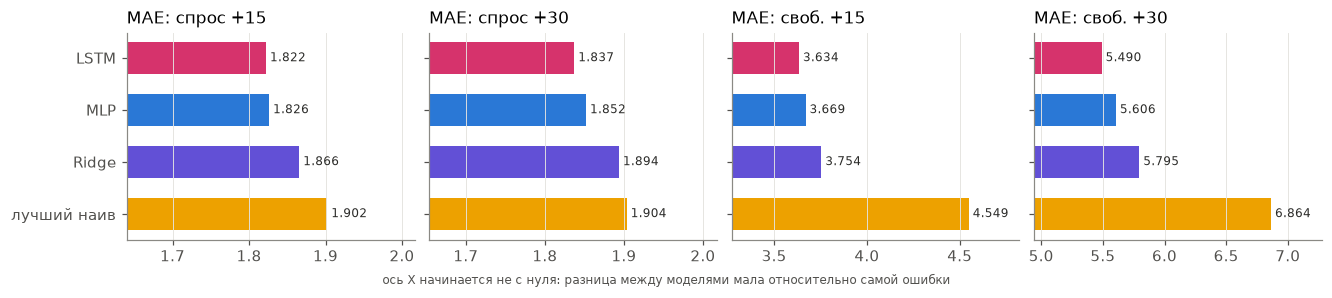

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.6), layout="constrained")
for k, (ax, t) in enumerate(zip(axes, TARGETS)):
    names = ["лучший наив", "Ridge", "MLP", "LSTM"]
    vals = [best_naive_mae[k], res2.loc["Ridge (линейная)", (t, "MAE")],
            res2.loc["MLP", (t, "MAE")], res2.loc["LSTM", (t, "MAE")]]
    ax.barh(range(4), vals, color=[C["profile"], C["ridge"], C["mlp"], C["lstm"]], height=0.62)
    for y_, v in enumerate(vals):
        ax.text(v, y_, f" {v:.3f}", va="center", fontsize=8, color="#2b2b29")
    lo = min(vals) * 0.9
    ax.set_xlim(lo, max(vals) * 1.06)
    ax.set_yticks(range(4), names if k == 0 else [""] * 4)
    ax.set_title(f"MAE: {t}", loc="left"); ax.grid(axis="y", visible=False)
fig.supxlabel("ось X начинается не с нуля: разница между моделями мала относительно самой ошибки",
              fontsize=8, color=C["fact"])
plt.show()

In [27]:
# Где разница: по зонам и в дождь (горизонт +30).
by_zone2 = pd.DataFrame({
    "MAE спрос+30 MLP": [mean_absolute_error(Y_TEST[Z_T == z, 1], P_MLP[Z_T == z, 1]) for z in range(Z)],
    "MAE спрос+30 LSTM": [mean_absolute_error(Y_TEST[Z_T == z, 1], P_LSTM[Z_T == z, 1]) for z in range(Z)],
    "MAE своб.+30 MLP": [mean_absolute_error(Y_TEST[Z_T == z, 3], P_MLP[Z_T == z, 3]) for z in range(Z)],
    "MAE своб.+30 LSTM": [mean_absolute_error(Y_TEST[Z_T == z, 3], P_LSTM[Z_T == z, 3]) for z in range(Z)],
}, index=ZONES)
for m in (rain_t, ~rain_t):
    by_zone2.loc["дождь" if m is rain_t else "без дождя"] = [
        mean_absolute_error(Y_TEST[m, k], P[m, k]) for k, P in ((1, P_MLP), (1, P_LSTM), (3, P_MLP), (3, P_LSTM))]
by_zone2["Δ спрос"] = 1 - by_zone2.iloc[:, 1] / by_zone2.iloc[:, 0]
by_zone2["Δ своб."] = 1 - by_zone2.iloc[:, 3] / by_zone2.iloc[:, 2]
by_zone2.style.format("{:.2f}").format("{:+.1%}", subset=["Δ спрос", "Δ своб."])

,MAE спрос+30 MLP,MAE спрос+30 LSTM,MAE своб.+30 MLP,MAE своб.+30 LSTM,Δ спрос,Δ своб.
sleep-1,1.33,1.26,4.07,4.13,+4.7%,-1.4%
sleep-2,1.31,1.31,4.06,4.07,+0.3%,-0.2%
center,2.50,2.42,9.75,9.08,+3.5%,+6.8%
office,2.34,2.36,6.38,6.48,-0.8%,-1.5%
airport,1.56,1.55,5.83,5.63,+0.5%,+3.4%
lounge,2.07,2.12,3.54,3.54,-2.5%,-0.0%
дождь,3.25,4.31,10.87,13.73,-32.6%,-26.4%
без дождя,1.81,1.77,5.46,5.25,+2.5%,+3.7%


### 10.3. Раннее предупреждение о дефиците: LSTM-классификатор

Та же LSTM с двумя логитами (дефицит через +15 / +30 мин) и BCE. Порог подбирается по F1 на валидации,
как для MLP-классификатора в §7.

In [28]:
lstm_clf, LINFOc = fit_lstm(XS, XC, Yc, *BEST_LSTM, classifier=True)
lpv, lps = lstm_clf(VAL), lstm_clf(TST)
rows = []
for k, hz in enumerate(("+15", "+30")):
    for name, pval, ptst in (("MLP", pv, ps), ("LSTM", lpv, lps)):
        th = ths[np.argmax([f1_score(Yc[VAL][:, k], pval[:, k] >= t) for t in ths])]
        yhat = (ptst[:, k] >= th).astype(int)
        rows.append({"горизонт": hz, "модель": name, "порог": th,
                     "precision": precision_score(YC_T[:, k], yhat), "recall": recall_score(YC_T[:, k], yhat),
                     "F1": f1_score(YC_T[:, k], yhat), "ROC-AUC": roc_auc_score(YC_T[:, k], ptst[:, k]),
                     "log-loss": log_loss(YC_T[:, k], np.clip(ptst[:, k], 1e-6, 1 - 1e-6))})
clf_cmp = pd.DataFrame(rows).set_index(["горизонт", "модель"])
clf_cmp.style.format("{:.3f}").format("{:.2f}", subset=["порог"])

### 10.4. Устойчивость к seed: MLP и LSTM

Пять seed для выбранной LSTM. Разница MLP − LSTM сравнивается с разбросом: если |Δ| меньше суммарного
std, на этих данных модели статистически неразличимы.

In [29]:
lstm_seed_maes, lstm_times = [], []
for s in range(5):
    t = time.time()
    pr, _ = fit_lstm(XS, XC, Y, *BEST_LSTM, seed=s)
    lstm_times.append(time.time() - t)
    P = to_levels(pr(TST))
    lstm_seed_maes.append([mean_absolute_error(Y_TEST[:, k], P[:, k]) for k in range(4)])
lstm_seed_maes = np.array(lstm_seed_maes)

seed_cmp = pd.DataFrame({
    "MLP MAE": seed_maes.mean(0), "MLP ± std": seed_maes.std(0),
    "LSTM MAE": lstm_seed_maes.mean(0), "LSTM ± std": lstm_seed_maes.std(0),
}, index=TARGETS)
seed_cmp["Δ (LSTM лучше на)"] = 1 - seed_cmp["LSTM MAE"] / seed_cmp["MLP MAE"]
seed_cmp["|Δ| / √(std²+std²)"] = ((seed_cmp["MLP MAE"] - seed_cmp["LSTM MAE"]).abs()
                                  / np.sqrt(seed_cmp["MLP ± std"] ** 2 + seed_cmp["LSTM ± std"] ** 2))
seed_cmp["LSTM: худший seed < лучшего наива"] = lstm_seed_maes.max(0) < best_naive
print(f"Время обучения одной модели: LSTM ≈ {np.mean(lstm_times):.0f} с на {DEV}, "
      f"MLP ≈ {grid_df.loc[grid_df['скрытые слои'] == str(BEST[0]), 'время, с'].iloc[0]:.0f} с на CPU")
seed_cmp.style.format("{:.3f}", subset=seed_cmp.columns[:4]).format("{:+.1%}", subset=["Δ (LSTM лучше на)"]).format(
    "{:.1f}", subset=["|Δ| / √(std²+std²)"])

Время обучения одной модели: LSTM ≈ 38 с на mps, MLP ≈ 5 с на CPU


,MLP MAE,MLP ± std,LSTM MAE,LSTM ± std,Δ (LSTM лучше на),|Δ| / √(std²+std²),LSTM: худший seed < лучшего наива
спрос +15,1.837,0.022,1.832,0.009,+0.3%,0.2,True
спрос +30,1.851,0.015,1.841,0.006,+0.5%,0.6,True
своб. +15,3.727,0.044,3.688,0.024,+1.1%,0.8,True
своб. +30,5.651,0.115,5.499,0.052,+2.7%,1.2,True


In [30]:
# Сводка «разница в эффективности MLP vs LSTM» (усреднение по 5 seed для регрессии).
summary_rows = []
for k, t in enumerate(TARGETS):
    summary_rows.append({"задача": f"MAE {t}", "MLP": seed_maes.mean(0)[k], "LSTM": lstm_seed_maes.mean(0)[k],
                         "LSTM лучше на": 1 - lstm_seed_maes.mean(0)[k] / seed_maes.mean(0)[k],
                         "значимо (|Δ| > 2σ)": seed_cmp["|Δ| / √(std²+std²)"].iloc[k] > 2})
for hz in ("+15", "+30"):
    for met in ("F1", "ROC-AUC"):
        a, b = clf_cmp.loc[(hz, "MLP"), met], clf_cmp.loc[(hz, "LSTM"), met]
        summary_rows.append({"задача": f"дефицит {hz}: {met}", "MLP": a, "LSTM": b,
                             "LSTM лучше на": b / a - 1, "значимо (|Δ| > 2σ)": None})
mlp_vs_lstm = pd.DataFrame(summary_rows).set_index("задача")
print(f"Параметров: MLP {mlp_params:,} · LSTM {LINFO['params']:,}; время обучения одной модели: "
      f"MLP ≈ {grid_df.loc[grid_df['скрытые слои'] == str(BEST[0]), 'время, с'].iloc[0]:.0f} с (CPU), LSTM ≈ {np.mean(lstm_times):.0f} с ({DEV})")
mlp_vs_lstm.style.format("{:.3f}", subset=["MLP", "LSTM"], na_rep="—").format(
    "{:+.1%}", subset=["LSTM лучше на"], na_rep="—").format(na_rep="—", subset=["значимо (|Δ| > 2σ)"])

Параметров: MLP 57,732 · LSTM 25,540; время обучения одной модели: MLP ≈ 5 с (CPU), LSTM ≈ 38 с (mps)


,MLP,LSTM,LSTM лучше на,значимо (|Δ| > 2σ)
задача,,,,
MAE спрос +15,1.837,1.832,+0.3%,False
MAE спрос +30,1.851,1.841,+0.5%,False
MAE своб. +15,3.727,3.688,+1.1%,False
MAE своб. +30,5.651,5.499,+2.7%,False
дефицит +15: F1,0.659,0.662,+0.5%,—
дефицит +15: ROC-AUC,0.918,0.921,+0.2%,—
дефицит +30: F1,0.616,0.624,+1.3%,—
дефицит +30: ROC-AUC,0.897,0.904,+0.7%,—


### 10.5. Итог сравнения MLP и LSTM

**Средняя точность: LSTM чуть лучше MLP, но в пределах шума.** По 5 seed LSTM выигрывает у MLP
по MAE на всех четырёх таргетах: спрос +0.3 % / +0.5 % (+15 / +30), свободные машины +1.1 % / +2.7 %.
Ни одна разница не превышает 2σ разброса по seed (максимум 1.2σ, у «своб. +30»), так что на этих данных
модели **статистически неразличимы**. По RMSE картина обратная на трёх таргетах из четырёх
(LSTM хуже на 1.4–1.9 %): LSTM реже ошибается немного, но чаще ошибается сильно.

**Дефицит:** у LSTM F1 0.66 / 0.62 и ROC-AUC 0.92 / 0.90, это на 0.2–1.3 % выше MLP, лучше и log-loss.
Разница тоже на уровне шума.

**Где модели расходятся.** LSTM стабильнее по seed (std в 1.8–2.5 раза меньше) и лучше в зонах с крупным
парком (center: −7 % MAE по свободным машинам). Но **в дождь LSTM ошибается сильно хуже MLP**:
спрос +30 на 33 % хуже, свободные машины на 26 % хуже. Именно в нештатных окнах MLP давал главный выигрыш
над профилем (§6.2). Вероятная причина: в обучении всего несколько дождевых эпизодов, и LSTM, увидевшая
каждую пятиминутку, переобучается на их конкретную форму, а не на флаг «идёт дождь». Дождевых окон
на тесте всего 288, поэтому оценка грубая, но риск реальный.

**Цена.** LSTM в 2 раза меньше по параметрам (25.5 тыс. против 57.7 тыс.), но обучается в ≈ 8 раз дольше
(≈ 38 с на GPU Apple против ≈ 5 с MLP на CPU, на CPU разрыв был бы ещё ≈ 8×).

**Вывод для M3:** рекуррентность на этом окне и этих признаках **пока не окупается**. Сигнал почти
целиком извлекают признаки (календарь, сезонный лаг, возвращающиеся водители), и MLP ими уже пользуется.
Чтобы LSTM стала обоснованным выбором, нужно: (1) закрыть провал в дождь (аугментация дождём,
больше дождевых дней в данных, §10.8); (2) показать выигрыш > 2σ по seed хотя бы по свободным машинам
или по дефициту; (3) проверить, даёт ли что-то multi-task-постановка (регрессия и дефицит одной сетью),
которой у MLP-бейзлайна нет.

## 11. Итог: выполнены ли цели

In [31]:
f1 = clf_res["F1"]; auc = clf_res["ROC-AUC"]
def f1_of(hz, prefix):
    return f1.loc[hz][[i for i in f1.loc[hz].index if i.startswith(prefix)]].iloc[0]
def auc_of(hz):
    return auc.loc[hz][[i for i in auc.loc[hz].index if i.startswith("MLP")]].iloc[0]

verdict = [
    ("Ц1 спрос", all(res.loc["MLP", (t, "MAE")] < res.loc[naive, (t, "MAE")].min() for t in TARGETS[:2]),
     f"выигрыш MAE у лучшего наива: {gain.loc['выигрыш MAE у лучшего наива', TARGETS[0]]:+.1%} / "
     f"{gain.loc['выигрыш MAE у лучшего наива', TARGETS[1]]:+.1%} (+15/+30); "
     f"у «как сейчас»: {gain.loc['… у «как сейчас»', TARGETS[1]]:+.1%} на +30"),
    ("Ц2 своб. машины", all(res.loc["MLP", (t, "MAE")] < res.loc[naive, (t, "MAE")].min()
                           and gain.loc["… у «как сейчас»", t] >= 0.10 for t in TARGETS[2:]),
     f"выигрыш у «как сейчас»: {gain.loc['… у «как сейчас»', TARGETS[2]]:+.1%} / {gain.loc['… у «как сейчас»', TARGETS[3]]:+.1%}"),
    ("Ц3 дефицит", all(f1_of(hz, "MLP") > f1_of(hz, "дефицит сейчас") and auc_of(hz) >= 0.85 for hz in ("+15", "+30")),
     f"F1 MLP {f1_of('+15', 'MLP'):.2f} / {f1_of('+30', 'MLP'):.2f} против {f1_of('+15', 'дефицит'):.2f} / "
     f"{f1_of('+30', 'дефицит'):.2f}; AUC {auc_of('+15'):.2f} / {auc_of('+30'):.2f}"),
    ("Ц4 устойчивость", bool((seed_maes.max(0) < best_naive).all() and (seed_df.iloc[:, -1] > 1).all()),
     f"худший из 5 seed всё равно лучше лучшего наива по всем 4 таргетам; запас ≥ {seed_df.iloc[:, -1].min():.0f} std"),
]
pd.DataFrame(verdict, columns=["цель", "выполнена", "факт"]).set_index("цель")

,выполнена,факт
цель,,
Ц1 спрос,True,выигрыш MAE у лучшего наива: +4.0% / +2.7% (+1...
Ц2 своб. машины,True,выигрыш у «как сейчас»: +19.3% / +18.3%
Ц3 дефицит,True,F1 MLP 0.66 / 0.62 против 0.55 / 0.52; AUC 0.9...
Ц4 устойчивость,True,худший из 5 seed всё равно лучше лучшего наива...


### Выводы

1. **Прогнозирование MLP на данных симулятора работает.** Даже небольшой персептрон из двух скрытых
   слоёв на окне истории 6 ч (лаги подаются как плоский вектор признаков) стабильно обходит все наивные
   прогнозы по спросу и по свободным машинам на обоих горизонтах. Таблица выше показывает это
   численно для каждой из целей Ц1–Ц4.
2. **Спрос** MLP прогнозирует близко к теоретическому пределу: MAE лишь немного выше шумового пола
   пуассоновского потока. Средний выигрыш у исторического профиля небольшой (+3–4 %), потому что точечная
   5-минутка с λ ≈ 5 в основном состоит из шума. Зато **в дождь** MLP ошибается примерно на треть меньше
   профиля (§6.2): модель реагирует на внешний шок, а наив нет.
3. **Свободные машины** — задача, где сеть даёт наибольшую практическую пользу: persistence
   запаздывает, а MLP учитывает ближайшие высадки и уход машин на заказы. Признак «возвращающиеся
   водители» из расписания поездок заметно снижает ошибку (§8.2).
4. **Дефицит** предсказуем за 15–30 минут с ROC-AUC около 0.9 и F1 выше persistence. Это прямой
   вход для предиктивной политики C в M6.
5. Нелинейность даёт выигрыш у Ridge на тех же признаках, но умеренный. Основная сила здесь в
   **признаках** (календарь, сезонный лаг, возвращающиеся водители), и модель M3 их стоит унаследовать.
6. **LSTM против MLP (§10).** На тех же данных и признаках LSTM в среднем лучше на 0.3–2.7 % по MAE и на
   0.2–1.3 % по F1/AUC дефицита, но разница меньше разброса по seed. В дождь LSTM заметно хуже MLP
   (на 26–33 %), а обучается в ≈ 8 раз дольше. Сейчас рекуррентность себя не окупает.

### Что взять в веху M3

* Схема признаков, анти-утечное разбиение днями и ранняя остановка по валидационным дням из этого
  ноутбука переносятся в `m3-dataset` без изменений.
* MLP — **третий бейзлайн** для сводной таблицы «наив-1 / наив-2 / MLP / LSTM». Первая проверка (§10)
  показала, что LSTM обходит его лишь в пределах шума и проваливается в дождь. Критерий приёмки LSTM в M3:
  выигрыш у MLP > 2σ по seed и отсутствие деградации на дождевых окнах.
* Окно 3/6/12 ч (§10.5) по этому эксперименту влияет на результат слабо. Дефолт 6 ч приемлем,
  а для LSTM сравнение стоит повторить.
* По §10.6 эксперимент склоняет к **накопленному** таргету спроса или к хранению обоих.

*Ограничения:* данные синтетические (один seed мира, 30 дней). В тестовых 6 сутках всего два
дождевых эпизода, поэтому вывод о реакции на дождь (§6.2) предварительный. Для надёжной проверки
нужна догенерация данных с другим seed (§10.8). Выигрыш по точечному спросу численно невелик
(+3–4 % у профиля), но устойчив к seed (§9).